# 02 · Reaction Kinetics: Order, Rate Constant and Activation Energy for the Oxidation of Ethanol by Dichromate

**Sources:**
- **Part A: my own data** (SFC1003, Experiment 3, Part b): absorbance of Cr₂O₇²⁻ at 440 nm followed for 90 minutes.
- **Parts B and C: model data supplied by the course** (SFC1003, Experiment 4). These are *not* my measurements. I use them to practise the full kinetic workflow.

**Why this matters in pharma:** the same mathematics (integrated rate laws, fitting the order, the Arrhenius equation) underpins **drug-stability testing** and shelf-life prediction. Part C makes that link explicitly.

Cr₂O₇²⁻ + 3 CH₃CH₂OH + 8 H⁺ → 2 Cr³⁺ + 3 CH₃CHO + 7 H₂O

Ethanol and acid are in large excess, so the rate depends only on [Cr₂O₇²⁻] (pseudo-order conditions).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
R = 8.314  # J mol-1 K-1

---
## Part A: My own data

### A1. From absorbance to concentration
I use the calibration from **Notebook 01** (same practical, Part a). It's refitted here so this notebook runs on its own.

In [2]:
# Calibration standards (Notebook 01)
c_std = 0.0040 * 10 / np.array([10, 20, 30, 40, 50, 60])
A_std = np.array([1.368, 0.669, 0.481, 0.367, 0.286, 0.251])
cal = stats.linregress(c_std, A_std)
print(f"Calibration: A = {cal.slope:.1f}·c + {cal.intercept:.4f}")

kin = pd.DataFrame({
    "t_min": [5, 10, 20, 30, 40, 50, 60, 70, 80, 90],
    "A_440": [0.931, 0.721, 0.461, 0.289, 0.226, 0.196, 0.148, 0.130, 0.115, 0.110],
})
kin["c_M"] = (kin["A_440"] - cal.intercept) / cal.slope
t = kin["t_min"].to_numpy(float)
c = kin["c_M"].to_numpy()
kin.round(6)

Calibration: A = 334.2·c + 0.0245


,t_min,A_440,c_M
0,5,0.931,0.002713
1,10,0.721,0.002084
2,20,0.461,0.001306
3,30,0.289,0.000791
4,40,0.226,0.000603
5,50,0.196,0.000513
6,60,0.148,0.000370
7,70,0.130,0.000316
8,80,0.115,0.000271
9,90,0.110,0.000256


### A2. The textbook test: which integrated rate law gives a straight line?

| Order | Linear plot | Slope |
|---|---|---|
| 0 | [A] vs t | −k |
| 1 | ln[A] vs t | −k |
| 2 | 1/[A] vs t | +k |

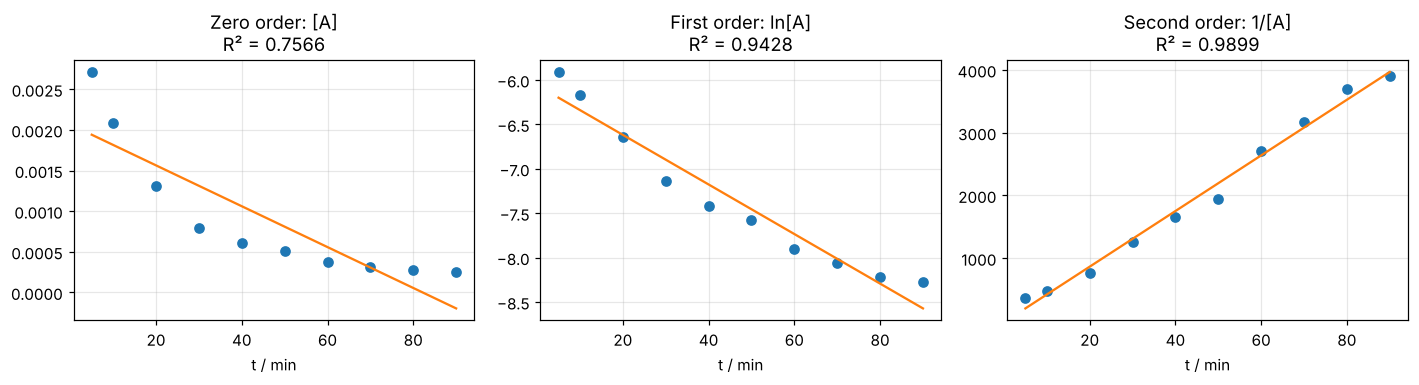

,model,slope,R²
0,Zero order: [A],-0.00003,0.75663
1,First order: ln[A],-0.02791,0.94281
2,Second order: 1/[A],44.32683,0.98990


In [3]:
tests = {"Zero order: [A]": c, "First order: ln[A]": np.log(c), "Second order: 1/[A]": 1 / c}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
rows = []
for ax, (name, yv) in zip(axes, tests.items()):
    r = stats.linregress(t, yv)
    rows.append({"model": name, "slope": r.slope, "R²": r.rvalue**2})
    ax.plot(t, yv, "o")
    ax.plot(t, r.intercept + r.slope * t, "-")
    ax.set_title(f"{name}\nR² = {r.rvalue**2:.4f}")
    ax.set_xlabel("t / min")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(5)

Going by R² alone, **second order wins** (R² ≈ 0.99), and the first-order plot visibly curves. If I stopped here I'd conclude the reaction is second order in dichromate.

But look at the raw data: the absorbance **levels off at about 0.11 instead of falling to zero**. No simple rate law predicts a non-zero floor, and a second-order curve, with its long slow tail, happens to imitate one. So the high R² may be fitting an artefact rather than the chemistry.

### A3. A better model: first order with a baseline

A likely explanation is that the **Cr³⁺ product also absorbs weakly at 440 nm** (aqueous Cr³⁺ has a broad absorption band near 410 nm). As dichromate disappears, Cr³⁺ builds up, so the measured absorbance tends towards a constant value, A∞, rather than zero.

I work directly in absorbance, because the baseline is a property of the solution, not of dichromate:

**A(t) = (A₀ − A∞)·e^(−k′t) + A∞**

and compare it with the alternatives using non-linear least squares and the corrected Akaike Information Criterion (AICc), which penalises extra parameters.

In [4]:
A = kin["A_440"].to_numpy()

def first(t, A0, k):            return A0 * np.exp(-k * t)
def first_base(t, A0, k, Ainf): return (A0 - Ainf) * np.exp(-k * t) + Ainf
def second(t, A0, k):           return 1 / (1 / A0 + k * t)   # k here in absorbance units

models = {
    "1st order (to zero)":     (first,      [1.2, 0.03]),
    "2nd order":               (second,     [1.2, 0.1]),
    "1st order + baseline A∞": (first_base, [1.2, 0.05, 0.1]),
}

def aicc(rss, n, p):
    return n * np.log(rss / n) + 2 * p + 2 * p * (p + 1) / (n - p - 1)

results, fits = [], {}
for name, (f, p0) in models.items():
    popt, pcov = curve_fit(f, t, A, p0=p0, maxfev=10000)
    rss = np.sum((A - f(t, *popt))**2)
    fits[name] = (f, popt, pcov)
    results.append({"model": name, "parameters": len(popt), "RSS": rss, "AICc": aicc(rss, len(t), len(popt))})

res = pd.DataFrame(results)
res["ΔAICc"] = res["AICc"] - res["AICc"].min()
res.sort_values("AICc").round(6)

,model,parameters,RSS,AICc,ΔAICc
2,1st order + baseline A∞,3,0.000990,-82.203818,0.000000
1,2nd order,2,0.006110,-68.290583,13.913235
0,1st order (to zero),2,0.021738,-55.598696,26.605122


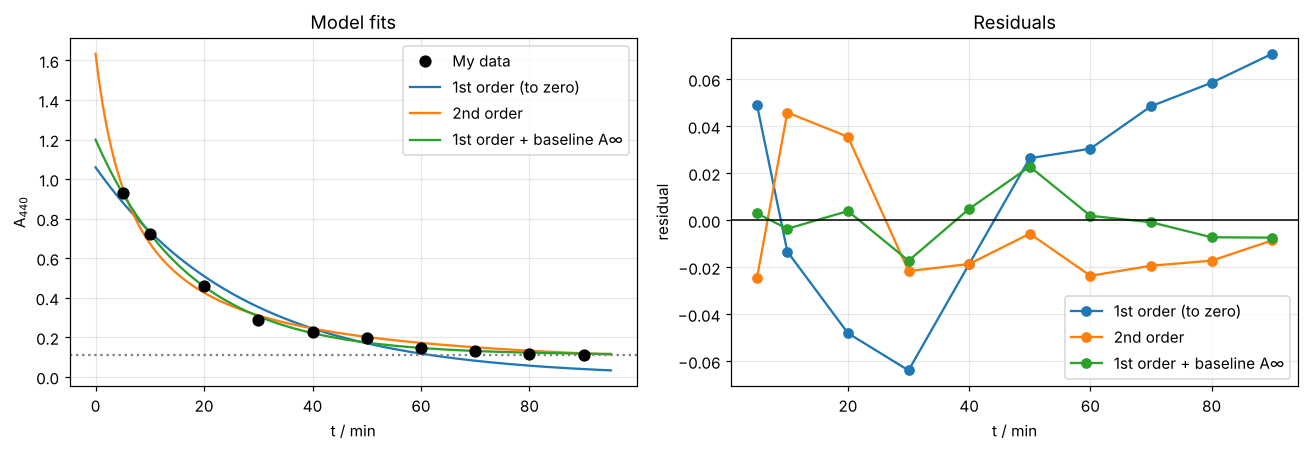

In [5]:
tt = np.linspace(0, 95, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(t, A, "ko", ms=7, label="My data", zorder=3)
for name, (f, popt, _) in fits.items():
    ax1.plot(tt, f(tt, *popt), label=name)
    ax2.plot(t, A - f(t, *popt), "o-", label=name)
ax1.axhline(fits["1st order + baseline A∞"][1][2], ls=":", c="grey")
ax1.set_xlabel("t / min"); ax1.set_ylabel("A$_{440}$"); ax1.set_title("Model fits"); ax1.legend()
ax2.axhline(0, c="k", lw=1)
ax2.set_xlabel("t / min"); ax2.set_ylabel("residual"); ax2.set_title("Residuals"); ax2.legend()
plt.tight_layout(); plt.show()

In [6]:
f, popt, pcov = fits["1st order + baseline A∞"]
perr = np.sqrt(np.diag(pcov))
tcrit = stats.t.ppf(0.975, len(t) - 3)
A0, k1, Ainf = popt
print(f"k′  = {k1:.4f} ± {tcrit*perr[1]:.4f} min⁻¹ (95% CI)")
print(f"t½  = {np.log(2)/k1:.1f} min")
print(f"A∞  = {Ainf:.3f} ± {tcrit*perr[2]:.3f}")
print(f"A₀ (extrapolated to t = 0) = {A0:.3f}")

# Plausibility check on the Cr3+ explanation
c0_dichromate = (A0 - cal.intercept) / cal.slope
c_Cr3 = 2 * c0_dichromate                       # 2 Cr3+ per Cr2O7 2-
eps_needed = Ainf / c_Cr3
print(f"\nIf all ~{c0_dichromate*1e3:.2f} mM dichromate → {c_Cr3*1e3:.2f} mM Cr³⁺,")
print(f"the baseline needs ε(Cr³⁺, 440 nm) ≈ {eps_needed:.0f} M⁻¹ cm⁻¹")

k′  = 0.0573 ± 0.0052 min⁻¹ (95% CI)
t½  = 12.1 min
A∞  = 0.111 ± 0.017
A₀ (extrapolated to t = 0) = 1.199

If all ~3.51 mM dichromate → 7.03 mM Cr³⁺,
the baseline needs ε(Cr³⁺, 440 nm) ≈ 16 M⁻¹ cm⁻¹


**Interpretation**

- The first-order-plus-baseline model has the lowest AICc and the most random residuals, even after the penalty for its extra parameter. The second-order fit leaves a systematic pattern in its residuals.
- The baseline needs Cr³⁺ to absorb with ε of only about 16 M⁻¹ cm⁻¹ at 440 nm. That's the right order of magnitude for a weak d–d band of Cr³⁺, so the explanation is chemically plausible. To confirm it, I'd measure a Cr³⁺ standard at 440 nm, or record full spectra rather than a single wavelength.
- **Conclusion:** the reaction is **pseudo-first-order in dichromate**, with k′ ≈ 0.057 min⁻¹ and t½ ≈ 12 min. The "second-order" result was an artefact of ignoring the product's absorbance.

*Lesson:* the best R² isn't automatically the right model. Plotting the raw data and the residuals, and asking what is physically happening in the cuvette, changed my conclusion.

---
## Part B: Confirming the order with model data (course-supplied)

The pro-forma asked us to calculate rate = k′[Cr₂O₇²⁻] and then plot ln(rate) against ln[Cr₂O₇²⁻] to find the order. That method is **circular**: the rates are calculated *assuming* first order, so the slope is 1 by construction.

A fairer test is to estimate the rate **directly from the concentration-time data** by numerical differentiation, then fit ln(rate) against ln[c]. In that case the slope is a genuine measurement of the order.

In [7]:
model = pd.DataFrame({
    "t_min": [0, 10, 20, 30, 40, 50, 60, 70, 80],
    "c_M":   [0.00356, 0.00308, 0.00267, 0.00235, 0.00196, 0.00173, 0.00153, 0.00132, 0.00114],
})
tm, cm = model["t_min"].to_numpy(float), model["c_M"].to_numpy()

# Pseudo-first-order rate constant from ln[c] vs t
r1 = stats.linregress(tm, np.log(cm))
k_model = -r1.slope
print(f"k′ = {k_model:.4f} ± {stats.t.ppf(0.975, len(tm)-2)*r1.stderr:.4f} min⁻¹,  R² = {r1.rvalue**2:.4f}")

# Rate directly from the data: central differences, -dc/dt
model["rate"] = -np.gradient(cm, tm)
rr = stats.linregress(np.log(cm), np.log(model["rate"]))
ci = stats.t.ppf(0.975, len(tm)-2) * rr.stderr
print(f"Order from ln(rate) vs ln[c] = {rr.slope:.2f} ± {ci:.2f} (95% CI)")

k′ = 0.0142 ± 0.0004 min⁻¹,  R² = 0.9991
Order from ln(rate) vs ln[c] = 0.94 ± 0.18 (95% CI)


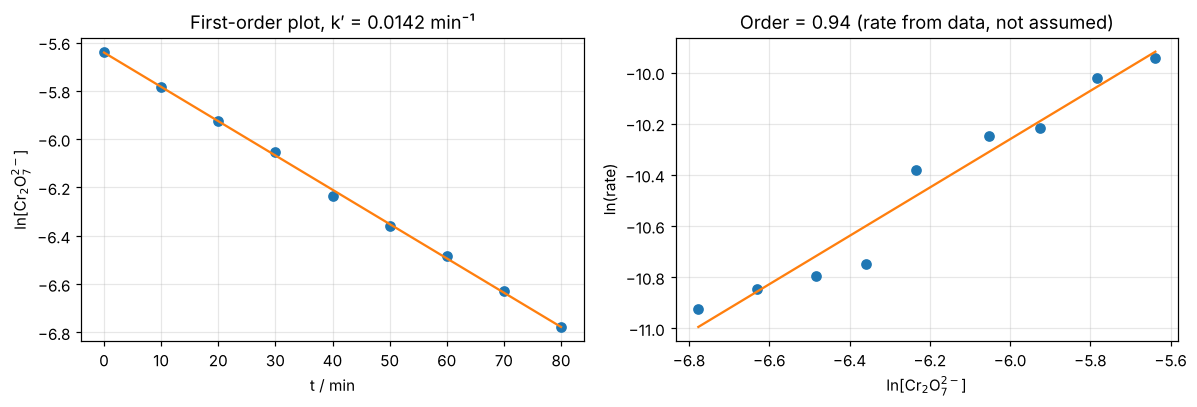

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(tm, np.log(cm), "o"); ax1.plot(tm, r1.intercept + r1.slope*tm, "-")
ax1.set_xlabel("t / min"); ax1.set_ylabel("ln[Cr$_2$O$_7^{2-}$]"); ax1.set_title(f"First-order plot, k′ = {k_model:.4f} min⁻¹")
lx = np.log(cm)
ax2.plot(lx, np.log(model["rate"]), "o"); ax2.plot(lx, rr.intercept + rr.slope*lx, "-")
ax2.set_xlabel("ln[Cr$_2$O$_7^{2-}$]"); ax2.set_ylabel("ln(rate)"); ax2.set_title(f"Order = {rr.slope:.2f} (rate from data, not assumed)")
plt.tight_layout(); plt.show()

The order measured directly comes out close to 1, within its confidence interval, so the model data are consistent with **first order in dichromate**. That matches what I found in my own data once the baseline was accounted for.

(Pseudo-first-order k′ depends on the ethanol and acid concentrations, so the k′ values in Parts A and B aren't expected to be equal.)

---
## Part C: Activation energy and a shelf-life-style prediction (course-supplied model data)

The Arrhenius equation, **ln k = ln A − Eₐ/(RT)**, means a plot of ln k against 1/T should be a straight line with slope −Eₐ/R.

Pharmaceutical **accelerated stability studies** (ICH Q1A) rely on this: degradation is measured quickly at high temperature, then extrapolated to storage conditions. Here I apply the same idea to estimate how fast the reaction would go at 25 °C.

In [9]:
arr = pd.DataFrame({"T_C": [35, 45, 55, 65, 75, 85],
                    "k_min": [0.0268, 0.0486, 0.0851, 0.144, 0.236, 0.378]})
arr["T_K"] = arr["T_C"] + 273.15
x_arr, y_arr = 1 / arr["T_K"].to_numpy(), np.log(arr["k_min"].to_numpy())
ra = stats.linregress(x_arr, y_arr)
tc = stats.t.ppf(0.975, len(arr) - 2)

Ea = -ra.slope * R / 1000
Ea_ci = tc * ra.stderr * R / 1000
A_pre = np.exp(ra.intercept)
print(f"Eₐ = {Ea:.1f} ± {Ea_ci:.1f} kJ mol⁻¹ (95% CI),  R² = {ra.rvalue**2:.5f}")
print(f"A  = {A_pre:.2e} min⁻¹")

Eₐ = 48.5 ± 0.1 kJ mol⁻¹ (95% CI),  R² = 1.00000
A  = 4.55e+06 min⁻¹


k(25 °C) = 0.01419 min⁻¹  (95% CI 0.01415–0.01423)
Part B k′ (model data)  = 0.01419 min⁻¹  → consistent with ~25 °C
t½(25 °C) = 49 min,  t90(25 °C) = 7.4 min


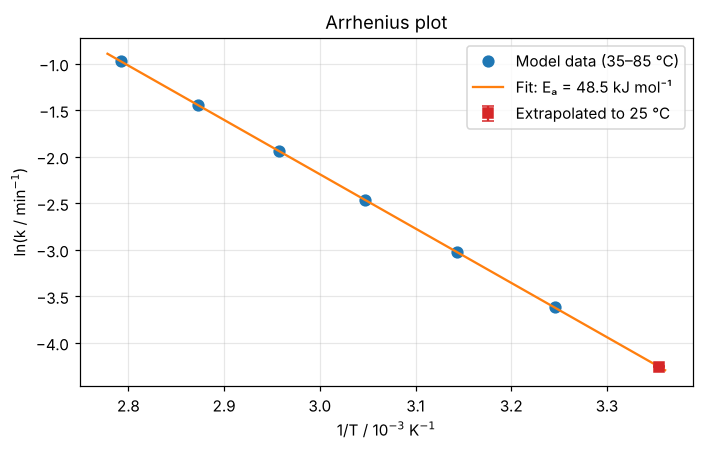

In [10]:
# Extrapolate to 25 °C, with a 95% prediction interval
T25 = 298.15; x0 = 1 / T25
n_a = len(x_arr); s_res = np.sqrt(np.sum((y_arr - (ra.intercept + ra.slope*x_arr))**2) / (n_a - 2))
se_pred = s_res * np.sqrt(1/n_a + (x0 - x_arr.mean())**2 / np.sum((x_arr - x_arr.mean())**2))
lnk25 = ra.intercept + ra.slope * x0
k25, k25_lo, k25_hi = np.exp(lnk25), np.exp(lnk25 - tc*se_pred), np.exp(lnk25 + tc*se_pred)

t_half = np.log(2) / k25
t90 = np.log(100/90) / k25    # time for 10% loss, the usual shelf-life definition
print(f"k(25 °C) = {k25:.5f} min⁻¹  (95% CI {k25_lo:.5f}–{k25_hi:.5f})")
print(f"Part B k′ (model data)  = {k_model:.5f} min⁻¹  → consistent with ~25 °C")
print(f"t½(25 °C) = {t_half:.0f} min,  t90(25 °C) = {t90:.1f} min")

xx = np.linspace(x0 * 1.002, x_arr.min() * 0.995, 100)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(x_arr * 1e3, y_arr, "o", ms=7, label="Model data (35–85 °C)")
ax.plot(xx * 1e3, ra.intercept + ra.slope * xx, "-", label=f"Fit: Eₐ = {Ea:.1f} kJ mol⁻¹")
ax.errorbar(x0 * 1e3, lnk25, yerr=tc*se_pred, fmt="s", c="C3", capsize=4, label="Extrapolated to 25 °C")
ax.set_xlabel("1/T / 10$^{-3}$ K$^{-1}$"); ax.set_ylabel("ln(k / min$^{-1}$)")
ax.set_title("Arrhenius plot"); ax.legend()
plt.tight_layout(); plt.show()

In [11]:
# How much faster per 10 °C? (the rule of thumb used in stability work)
for T1 in (25, 35):
    ratio = np.exp(-Ea*1000/R * (1/(T1+283.15) - 1/(T1+273.15)))
    print(f"k({T1+10} °C) / k({T1} °C) = {ratio:.2f}")

k(35 °C) / k(25 °C) = 1.89
k(45 °C) / k(35 °C) = 1.81


**Interpretation**
- Eₐ ≈ 48.5 kJ mol⁻¹, with an almost perfect Arrhenius line (expected for model data).
- Each 10 °C rise speeds the reaction up by roughly 1.8–1.9×. That's close to the "doubling per 10 °C" rule of thumb behind accelerated stability testing.
- **Cross-check:** the extrapolated k(25 °C) ≈ 0.0142 min⁻¹ matches the k′ I found independently from the Part B model data (0.0142 min⁻¹). That suggests the Part B run represents about 25 °C, and the two model datasets agree with each other.
- The 25 °C estimate is an **extrapolation outside the measured range**. Its confidence interval is tiny here only because model data sit almost perfectly on the line. Real measurements would scatter, and the interval would widen the further the extrapolation goes. That's why ICH stability guidelines require real-time data to confirm predictions made at accelerated conditions.

## Summary

| Result | Value | Data |
|---|---|---|
| Order in Cr₂O₇²⁻ | pseudo-first order | mine (A) and model (B) |
| k′ (my experiment) | ≈ 0.057 min⁻¹, t½ ≈ 12 min | mine |
| Apparent "2nd order" | artefact of Cr³⁺ absorbance baseline | mine |
| Order measured directly (not assumed) | ≈ 1 | model |
| Eₐ | ≈ 48.5 kJ mol⁻¹ | model |
| k at 25 °C (extrapolated) | ≈ 0.0142 min⁻¹, matches Part B k′ | model |

**Skills shown:** integrated rate laws, non-linear least squares, model comparison with AICc, residual analysis, numerical differentiation, Arrhenius analysis with confidence and prediction intervals, and spotting a circular analysis in the original method.